# arXiv AI/ML Research Abstracts: NLP Analysis

Exploratory text analysis of 7,701 arXiv AI/ML paper abstracts (Sep 2025 – Apr 2026): cleaning, keyword and TF-IDF analysis, LDA topic modelling, TF-IDF search, and optional embedding / BERTopic extensions.

- **Data:** [arXiv AI/ML Research Papers 2025-2026 (Kaggle, `shree0910`)](https://www.kaggle.com/datasets/shree0910/arxiv-aiml-research-papers-20252026) - download `arxiv_ai_ml_papers.csv` and place it next to this notebook, or set `FILE_PATH` in the first code cell.
- **Run status:** sections 1-12 were executed and their outputs are saved, except the three cells added later (monthly record counts, monthly phrase shares, final data-driven summary, and the dataset-facts cell), which must be re-run to refresh their outputs. The embedding (section 13) and BERTopic (section 14) sections are switched off (`RUN_EMBEDDINGS = False`, `RUN_BERTOPIC = False`) and have **not** been run.
- **Environment:** see `requirements.txt` in the repository root.


# 1. Setup and reproducibility

In [10]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
FILE_NAME = "arxiv_ai_ml_papers.csv"
FILE_PATH = None  # Optional: set to the full path if auto-detection does not find the CSV

candidate_paths = []
if FILE_PATH:
    candidate_paths.append(Path(FILE_PATH))
candidate_paths += [
    Path("/kaggle/input/datasets/shree0910/arxiv-aiml-research-papers-20252026/arxiv_ai_ml_papers.csv"),
    Path("/kaggle/input/arxiv-aiml-research-papers-20252026/arxiv_ai_ml_papers.csv"),
    Path.cwd() / FILE_NAME,
    Path("/mnt/data") / FILE_NAME,
]

file_path = next((p for p in candidate_paths if p.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        f"Could not find {FILE_NAME}. Set FILE_PATH to the actual CSV path. "
        "In Kaggle, confirm the dataset is added under Notebook > Add Input."
    )

print(f"Loading: {file_path}")
df_raw = pd.read_csv(file_path, low_memory=False)
df = df_raw.copy()
print(f"Raw shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Loading: /kaggle/input/datasets/shree0910/arxiv-aiml-research-papers-20252026/arxiv_ai_ml_papers.csv
Raw shape: 7,701 rows × 26 columns


,paper_id,title,authors,num_authors,first_author,abstract,abstract_length,word_count,primary_category,all_categories,...,journal_ref,comment,has_doi,doi,arxiv_url,pdf_url,is_large_collaboration,is_updated,update_lag_days,days_since_submission
0,2604.26951v1,Turning the TIDE: Cross-Architecture Distillat...,Gongbo Zhang; Wen Wang; Ye Tian; Li Yuan,4,Gongbo Zhang,Diffusion large language models (dLLMs) offer ...,1269,167,cs.CL,cs.CL; cs.AI; cs.LG,...,Not Available,"15 pages, 3 figures. Code: https://github.com/...",0,Not Available,https://arxiv.org/abs/2604.26951v1,https://arxiv.org/pdf/2604.26951v1,0,0,0,1
1,2604.26231v1,ProMax: Exploring the Potential of LLM-derived...,Yi Zhang; Yiwen Zhang; Kai Zheng; Tong Chen; H...,5,Yi Zhang,The remarkable text understanding and generati...,1748,233,cs.IR,cs.IR,...,Not Available,"11 pages, 8 figures, accepted by SIGIR 2026",0,Not Available,https://arxiv.org/abs/2604.26231v1,https://arxiv.org/pdf/2604.26231v1,0,0,0,1
2,2604.26567v1,AirZoo: A Unified Large-Scale Dataset for Grou...,Xiaoya Cheng; Rouwan Wu; Xinyi Liu; Zeyu Cui; ...,9,Xiaoya Cheng,Despite the rapid progress in data-driven 3D v...,1692,217,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26567v1,https://arxiv.org/pdf/2604.26567v1,0,0,0,1
3,2604.26565v1,"DenseStep2M: A Scalable, Training-Free Pipelin...",Mingji Ge; Qirui Chen; Zeqian Li; Weidi Xie,4,Mingji Ge,Long-term video understanding requires interpr...,1758,204,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26565v1,https://arxiv.org/pdf/2604.26565v1,0,0,0,1
4,2604.26520v1,3D-LENS: A 3D Lifting-based Elevated Novel-vie...,William Grolleau; Astrid Sabourin; Guillaume L...,4,William Grolleau,Aerial-Ground Re-Identification (AG-ReID) is c...,1418,174,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26520v1,https://arxiv.org/pdf/2604.26520v1,0,0,0,1


# 2. Understand the dataset
Review column names, types, missingness, and exact duplicates before choosing text fields. The code below prints sample values to make column mapping transparent.

In [12]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

missing = (df.isna().sum().rename("missing_count").to_frame())
missing["missing_percent"] = (missing["missing_count"] / max(len(df), 1) * 100).round(2)
display(missing.sort_values("missing_count", ascending=False))

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].dropna().astype(str).head(3).tolist())

Column names:
['paper_id', 'title', 'authors', 'num_authors', 'first_author', 'abstract', 'abstract_length', 'word_count', 'primary_category', 'all_categories', 'num_categories', 'submitted_date', 'updated_date', 'year', 'month', 'has_journal_ref', 'journal_ref', 'comment', 'has_doi', 'doi', 'arxiv_url', 'pdf_url', 'is_large_collaboration', 'is_updated', 'update_lag_days', 'days_since_submission']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7701 entries, 0 to 7700
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   paper_id                7701 non-null   object
 1   title                   7701 non-null   object
 2   authors                 7701 non-null   object
 3   num_authors             7701 non-null   int64 
 4   first_author            7701 non-null   object
 5   abstract                7701 non-null   object
 6   abstract_length         7701 non-null 

,missing_count,missing_percent
paper_id,0,0.0
title,0,0.0
authors,0,0.0
num_authors,0,0.0
first_author,0,0.0
abstract,0,0.0
abstract_length,0,0.0
word_count,0,0.0
primary_category,0,0.0
all_categories,0,0.0


Exact duplicate rows: 0

--- paper_id ---
['2604.26951v1', '2604.26231v1', '2604.26567v1']

--- title ---
['Turning the TIDE: Cross-Architecture Distillation for Diffusion Large Language Models', 'ProMax: Exploring the Potential of LLM-derived Profiles with Distribution Shaping for Recommender Systems', 'AirZoo: A Unified Large-Scale Dataset for Grounding Aerial Geometric 3D Vision']

--- authors ---
['Gongbo Zhang; Wen Wang; Ye Tian; Li Yuan', 'Yi Zhang; Yiwen Zhang; Kai Zheng; Tong Chen; Hongzhi Yin', 'Xiaoya Cheng; Rouwan Wu; Xinyi Liu; Zeyu Cui; Yan Liu; Na Zhao; Yu Liu; Maojun Zhang; Shen Yan']

--- num_authors ---
['4', '5', '9']

--- first_author ---
['Gongbo Zhang', 'Yi Zhang', 'Xiaoya Cheng']

--- abstract ---
["Diffusion large language models (dLLMs) offer parallel decoding and bidirectional context, but state-of-the-art dLLMs require billions of parameters for competitive performance. While existing distillation methods for dLLMs reduce inference steps within a single archit

# 3. Detect the title, abstract, and year columns

In [13]:
def normalize_colname(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).lower()).strip("_")

normalized_columns = {normalize_colname(c): c for c in df.columns}

def choose_column(candidates):
    # Exact normalized alias first, then a conservative substring match
    for alias in candidates:
        if alias in normalized_columns:
            return normalized_columns[alias]
    for norm, original in normalized_columns.items():
        if any(alias in norm for alias in candidates if len(alias) >= 5):
            return original
    return None

ABSTRACT_COL = choose_column(["abstract", "summary", "paper_abstract", "description"])
TITLE_COL = choose_column(["title", "paper_title", "name"])
YEAR_COL = choose_column(["year", "published_year", "publication_year", "published", "date", "created"])

# If needed, replace None or the detected value with an exact column name, e.g.:
# ABSTRACT_COL = "abstract"
# TITLE_COL = "title"
# YEAR_COL = "year"

print("Detected title column:", TITLE_COL)
print("Detected abstract column:", ABSTRACT_COL)
print("Detected year/date column:", YEAR_COL)

if ABSTRACT_COL is None:
    raise ValueError("No abstract-like column detected. Set ABSTRACT_COL to the correct column name.")
if ABSTRACT_COL not in df.columns:
    raise KeyError(f"ABSTRACT_COL={ABSTRACT_COL!r} is not in the dataframe columns.")

Detected title column: title
Detected abstract column: abstract
Detected year/date column: year


# 4. Clean the data and prepare analysis fields

In [14]:
initial_rows = len(df)
df = df.drop_duplicates().copy()
rows_after_exact_dedup = len(df)

# Convert the abstract field to string while keeping missing values missing.
df["abstract_original"] = df[ABSTRACT_COL]
df["abstract_original"] = df["abstract_original"].where(df["abstract_original"].notna(), np.nan)
df = df[df["abstract_original"].notna()].copy()
df["abstract_original"] = df["abstract_original"].astype(str).str.strip()
df = df[df["abstract_original"].str.len() > 0].copy()

def clean_abstract(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\$[^$]*\$", " ", text)  # remove inline LaTeX math blocks when present
    text = re.sub(r"[^a-z0-9\s-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["abstract_clean"] = df["abstract_original"].map(clean_abstract)
df["word_count"] = df["abstract_clean"].str.split().str.len()
df["char_count"] = df["abstract_original"].str.len()

if TITLE_COL and TITLE_COL in df.columns:
    df["title_analysis"] = df[TITLE_COL].fillna("").astype(str).str.strip()
else:
    df["title_analysis"] = ""

if YEAR_COL and YEAR_COL in df.columns:
    # Supports numeric years and common date strings.
    year_numeric = pd.to_numeric(df[YEAR_COL], errors="coerce")
    date_year = pd.to_datetime(df[YEAR_COL], errors="coerce", utc=True).dt.year
    df["publication_year"] = year_numeric.where(year_numeric.between(1900, 2100), date_year)
else:
    df["publication_year"] = np.nan

# Month of submission: the dataset covers less than one year, so month (not year) is the comparable time unit.
DATE_COL = "submitted_date" if "submitted_date" in df.columns else YEAR_COL
if DATE_COL and DATE_COL in df.columns:
    df["publication_month"] = pd.to_datetime(df[DATE_COL], errors="coerce", utc=True).dt.tz_localize(None).dt.to_period("M")
else:
    df["publication_month"] = pd.NaT

print(f"Rows before cleaning: {initial_rows:,}")
print(f"Rows after exact duplicate removal: {rows_after_exact_dedup:,}")
print(f"Rows with usable abstracts: {len(df):,}")
print(f"Rows removed from initial data: {initial_rows - len(df):,}")
display(df[["title_analysis", "abstract_original", "abstract_clean", "word_count", "publication_year"]].head())

Rows before cleaning: 7,701
Rows after exact duplicate removal: 7,701
Rows with usable abstracts: 7,701
Rows removed from initial data: 0


,title_analysis,abstract_original,abstract_clean,word_count,publication_year
0,Turning the TIDE: Cross-Architecture Distillat...,Diffusion large language models (dLLMs) offer ...,diffusion large language models dllms offer pa...,173,2026
1,ProMax: Exploring the Potential of LLM-derived...,The remarkable text understanding and generati...,the remarkable text understanding and generati...,233,2026
2,AirZoo: A Unified Large-Scale Dataset for Grou...,Despite the rapid progress in data-driven 3D v...,despite the rapid progress in data-driven 3d v...,219,2026
3,"DenseStep2M: A Scalable, Training-Free Pipelin...",Long-term video understanding requires interpr...,long-term video understanding requires interpr...,204,2026
4,3D-LENS: A 3D Lifting-based Elevated Novel-vie...,Aerial-Ground Re-Identification (AG-ReID) is c...,aerial-ground re-identification ag-reid is con...,173,2026


# 5. Exploratory data analysis (EDA)

In [17]:
if df.empty:
    raise ValueError("No usable abstracts remain after cleaning. Check the selected abstract column.")

print("Abstract word-count summary:")
display(df["word_count"].describe().to_frame().T)
print("Abstracts with fewer than 10 words:", int((df["word_count"] < 10).sum()))
print("Abstracts with fewer than 30 words:", int((df["word_count"] < 30).sum()))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["word_count"].clip(upper=df["word_count"].quantile(0.99)), bins=60)
ax.set(title="Distribution of Abstract Lengths (upper 1% clipped for display)", xlabel="Word count", ylabel="Number of abstracts")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Abstract word-count summary:


,count,mean,std,min,25%,50%,75%,max
word_count,7701.0,180.847033,41.618961,26.0,152.0,180.0,210.0,299.0


In [ ]:
# Records per submission month. The first and last months of the collection window are partial.
if df["publication_month"].notna().any():
    month_counts = df["publication_month"].value_counts().sort_index()
    print(f"Submission dates: {df['publication_month'].min()} to {df['publication_month'].max()} (first and last months partial)")
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(month_counts.index.astype(str), month_counts.values)
    ax.set(title="Abstract Records by Submission Month", xlabel="Month", ylabel="Number of records")
    ax.grid(axis="y", alpha=0.25)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No usable submission date detected; time-based analysis will be skipped.")

# 6. Keyword and phrase frequency analysis

,term,frequency
0,models,6939
1,model,5634
2,framework,4559
3,data,4365
4,learning,3831
5,performance,3701
6,training,2839
7,reasoning,2708
8,existing,2623
9,language,2618


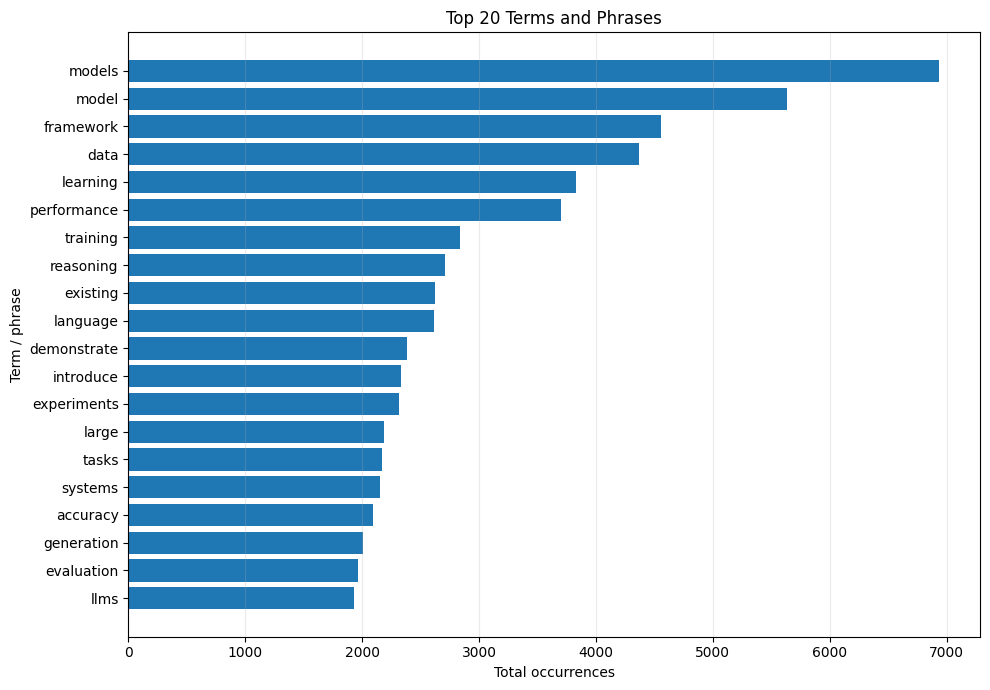

In [18]:
from sklearn.feature_extraction.text import CountVectorizer

DOMAIN_STOP_WORDS = [
    # Optional examples; adjust after inspecting the corpus:
    "paper", "study", "result", "results", "approach", "method", "methods",
    "propose", "proposed", "show", "shows", "using", "based"
]

count_vectorizer = CountVectorizer(
    stop_words=list(set(CountVectorizer(stop_words="english").get_stop_words()) | set(DOMAIN_STOP_WORDS)),
    ngram_range=(1, 2),
    min_df=2 if len(df) >= 20 else 1,
    max_df=0.95,
    max_features=10000,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9-]+\b"
)
X_counts = count_vectorizer.fit_transform(df["abstract_clean"])
terms = count_vectorizer.get_feature_names_out()
frequencies = np.asarray(X_counts.sum(axis=0)).ravel()
term_freq = pd.DataFrame({"term": terms, "frequency": frequencies}).sort_values("frequency", ascending=False)

display(term_freq.head(30).reset_index(drop=True))

plot_terms = term_freq.head(20).sort_values("frequency")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_terms["term"], plot_terms["frequency"])
ax.set(title="Top 20 Terms and Phrases", xlabel="Total occurrences", ylabel="Term / phrase")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# 7. TF–IDF: distinctive terms by document

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Use the same domain stop words; sklearn also removes standard English stop words.
tfidf_vectorizer = TfidfVectorizer(
    stop_words=list(set(CountVectorizer(stop_words="english").get_stop_words()) | set(DOMAIN_STOP_WORDS)),
    ngram_range=(1, 2),
    min_df=2 if len(df) >= 20 else 1,
    max_df=0.95,
    max_features=15000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9-]+\b"
)
X_tfidf = tfidf_vectorizer.fit_transform(df["abstract_clean"])
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
tfidf_summary = pd.DataFrame({"term": tfidf_terms, "mean_tfidf": mean_tfidf}).sort_values("mean_tfidf", ascending=False)
display(tfidf_summary.head(30).reset_index(drop=True))

# Show the highest-weight terms in a selected abstract.
example_idx = 0
row = X_tfidf[example_idx].toarray().ravel()
top_idx = row.argsort()[-12:][::-1]
print("Example abstract title:", df.iloc[example_idx]["title_analysis"] or "(title unavailable)")
print("Highest TF-IDF terms in this abstract:")
display(pd.DataFrame({"term": tfidf_terms[top_idx], "tfidf": row[top_idx]}))

,term,mean_tfidf
0,models,0.020770
1,model,0.018807
2,framework,0.016660
3,data,0.016401
4,learning,0.015406
5,performance,0.015104
6,training,0.012927
7,language,0.012452
8,existing,0.012242
9,reasoning,0.011707


Example abstract title: Turning the TIDE: Cross-Architecture Distillation for Diffusion Large Language Models
Highest TF-IDF terms in this abstract:


,term,tfidf
0,dllms,0.285060
1,cross-architecture,0.232887
2,teacher,0.196460
3,distillation,0.182832
4,student,0.166309
5,dllm,0.150015
6,parallel decoding,0.143963
7,humaneval,0.137547
8,inverts,0.137547
9,models dllms,0.135833


# 8. Topic modeling with Latent Dirichlet Allocation (LDA)

,topic,top_terms
0,0,"agents, user, systems, framework, agent, ai, r..."
1,1,"evaluation, model, detection, ai, systems, dat..."
2,2,"models, reasoning, language, llms, model, larg..."
3,3,"learning, neural, data, model, networks, model..."
4,4,"models, visual, data, model, framework, perfor..."
5,5,"optimization, control, framework, policy, lear..."


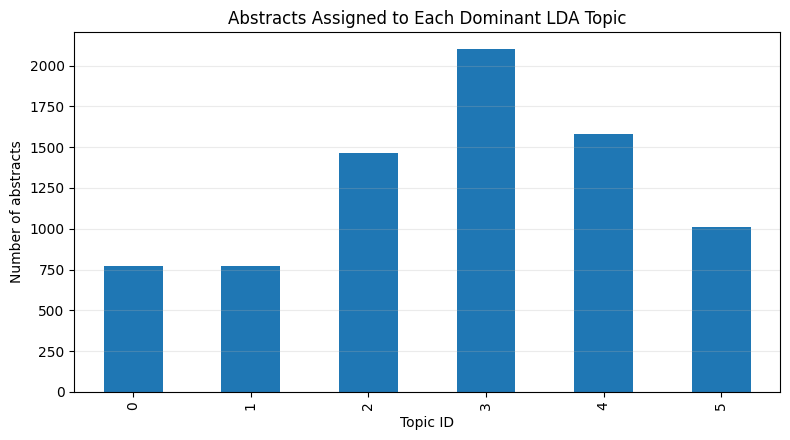


TOPIC 0 — top terms: agents, user, systems, framework, agent, ai, research, memory, human, models, design, language
- From Hidden Profiles to Governable Personalization: Recommender Systems in the Age of LLM Agents | topic probability=0.993
   Personalization has traditionally depended on platform-specific user models that are optimized for prediction but remain largely inaccessible to the people they describe. As LLM-based assistants increasingly mediate search, shopping, travel, and content access, this arrangement may be giving way to a new personalization stack in which user representation is no longer confined to isolated platforms. In this paper, we argue that the key issue is no ...
- On Accelerating Grounded Code Development for Research | topic probability=0.992
   A major challenge for niche scientific and technical domains in leveraging coding agents is the lack of access to up-to-date, domain- specific knowledge. Foundational models often demonstrate limited reasoning capa

In [20]:
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS = 6 if len(df) >= 30 else max(2, min(4, len(df)))
N_TOPICS = min(N_TOPICS, max(2, X_counts.shape[0]))
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    learning_method="batch",
    max_iter=20,
    doc_topic_prior=None,
    topic_word_prior=None
)

doc_topic = lda.fit_transform(X_counts)
df["dominant_topic"] = doc_topic.argmax(axis=1)
df["dominant_topic_probability"] = doc_topic.max(axis=1)

feature_names = count_vectorizer.get_feature_names_out()
topic_rows = []
for topic_id, weights in enumerate(lda.components_):
    top_ids = weights.argsort()[-12:][::-1]
    top_words = [feature_names[i] for i in top_ids]
    topic_rows.append({"topic": topic_id, "top_terms": ", ".join(top_words)})

topic_terms_df = pd.DataFrame(topic_rows)
display(topic_terms_df)

topic_sizes = df["dominant_topic"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
topic_sizes.plot(kind="bar", ax=ax)
ax.set(title="Abstracts Assigned to Each Dominant LDA Topic", xlabel="Topic ID", ylabel="Number of abstracts")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Inspect representative abstracts with the highest probability for each topic.
for topic_id in range(N_TOPICS):
    subset = df[df["dominant_topic"] == topic_id].sort_values("dominant_topic_probability", ascending=False).head(3)
    print(f"\nTOPIC {topic_id} — top terms: {topic_terms_df.loc[topic_terms_df.topic == topic_id, 'top_terms'].iloc[0]}")
    for _, row in subset.iterrows():
        title = row["title_analysis"] or "(title unavailable)"
        abstract = row["abstract_original"]
        print(f"- {title} | topic probability={row['dominant_topic_probability']:.3f}")
        print("  ", abstract[:450].replace("\n", " "), "..." if len(abstract) > 450 else "")

# 9. Phrase mentions by submission month
This section measures the share of abstracts in each submission month that mention selected phrases. The keywords are editable examples for AI/ML literature. Phrase matching is transparent but imperfect: it can miss synonyms and may count mentions that are not central to a paper. Topic trends based on LDA can be added after validating topic coherence.

In [ ]:
trend_patterns = {
    "Deep learning": r"\bdeep learning\b",
    "Transformer": r"\btransformers?\b",
    "Large language model": r"\blarge language models?\b|\bllms?\b",
    "Reinforcement learning": r"\breinforcement learning\b",
    "Graph neural network": r"\bgraph neural networks?\b|\bgnns?\b",
    "Diffusion model": r"\bdiffusion models?\b",
}
MIN_RECORDS_PER_MONTH = 100  # months with fewer records give unstable shares and are excluded

if df["publication_month"].notna().any():
    trend_df = df[df["publication_month"].notna()].copy()
    for label, pattern in trend_patterns.items():
        trend_df[label] = trend_df["abstract_original"].str.contains(pattern, case=False, regex=True, na=False)
    month_n = trend_df.groupby("publication_month").size()
    annual = trend_df.groupby("publication_month")[[*trend_patterns.keys()]].mean() * 100
    annual = annual[month_n >= MIN_RECORDS_PER_MONTH]
    annual.index.name = "month"
    excluded = month_n[month_n < MIN_RECORDS_PER_MONTH]
    if len(excluded):
        print("Months excluded (fewer than", MIN_RECORDS_PER_MONTH, "records):", {str(k): int(v) for k, v in excluded.items()})
    print("Records per month used:", {str(k): int(v) for k, v in month_n[annual.index].items()})
    display(annual.round(2))

    fig, ax = plt.subplots(figsize=(11, 6))
    x = annual.index.astype(str)
    for label in trend_patterns:
        ax.plot(x, annual[label], marker="o", linewidth=1.8, label=label)
    ax.set(title="Share of Abstracts Mentioning Selected AI/ML Topics, by Submission Month",
           xlabel="Submission month", ylabel="Abstracts mentioning phrase (%)")
    ax.legend(ncol=2, fontsize=9)
    ax.grid(alpha=0.25)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    annual = None
    print("Skipped: submission dates are unavailable or could not be parsed.")

> **How to read the monthly shares.** Each point is the share of that month's abstracts, within this sample, that mention the phrase. The sample covers only about seven months and may not be collected uniformly, so month-to-month changes are descriptive and are not evidence of long-term growth or decline. Phrase matching is lexical (for example "LLM" also matches abstracts that only use LLMs as a tool). A year-by-year comparison is deliberately not used: the "2025" label covers only 416 late-2025 records against 7,285 for 2026.

In [22]:
from sklearn.metrics.pairwise import cosine_similarity

# Edit this query to search for a topic of interest.
query = "large language models for scientific reasoning"
query_vec = tfidf_vectorizer.transform([clean_abstract(query)])
similarities = cosine_similarity(query_vec, X_tfidf).ravel()
top_n = min(10, len(df))
nearest = similarities.argsort()[-top_n:][::-1]
search_results = df.iloc[nearest].copy()
search_results["query_similarity"] = similarities[nearest]
cols_to_show = [c for c in ["title_analysis", "publication_year", "query_similarity", "abstract_original"] if c in search_results.columns]
display(search_results[cols_to_show].reset_index(drop=True))

,title_analysis,publication_year,query_similarity,abstract_original
0,PaperMind: Benchmarking Agentic Reasoning and ...,2026,0.325505,Understanding scientific papers requires more ...
1,S1-VL: Scientific Multimodal Reasoning Model w...,2026,0.278841,"We present S1-VL, a multimodal reasoning model..."
2,AI scientists produce results without reasonin...,2026,0.240058,Large language model (LLM)-based systems are i...
3,Cooperative Profiles Predict Multi-Agent LLM T...,2026,0.218505,Multi-agent systems built from teams of large ...
4,MiroThinker-1.7 & H1: Towards Heavy-Duty Resea...,2026,0.198913,"We present MiroThinker-1.7, a new research age..."
5,A Triadic Suffix Tokenization Scheme for Numer...,2026,0.177677,Standard subword tokenization methods fragment...
6,Large language models eroding science understa...,2026,0.168423,This paper is under review in AI and Ethics Th...
7,MeasHalu: Mitigation of Scientific Measurement...,2026,0.163551,The accurate extraction of scientific measurem...
8,Dual-Track CoT: Budget-Aware Stepwise Guidance...,2026,0.146125,Large Language Models (LLMs) solve many reason...
9,Do We Need Bigger Models for Science? Task-Awa...,2026,0.144491,Scientific knowledge discovery increasingly re...


# 11. Evidence-based conclusions generated from this dataset
The next cell creates concise observations using computed values. These are descriptive conclusions about this dataset only—not claims about all AI/ML research. Review the top terms and representative abstracts before assigning scientific meaning to a topic.

In [23]:
print("=" * 78)
print("DATA-DRIVEN SUMMARY")
print("=" * 78)
print(f"Usable abstracts analyzed: {len(df):,}")
print(f"Distinct abstract texts: {df['abstract_original'].nunique():,}")
print(f"Median abstract length: {df['word_count'].median():.1f} words")
print(f"Mean abstract length: {df['word_count'].mean():.1f} words")
print(f"Abstracts shorter than 30 words: {(df['word_count'] < 30).sum():,} ({(df['word_count'] < 30).mean()*100:.1f}%)")

if df["publication_month"].notna().any():
    first_m, last_m = df["publication_month"].min(), df["publication_month"].max()
    print(f"Submission window: {first_m} to {last_m} (first and last months partial)")
    print(f"Records with parsed submission date: {df['publication_month'].notna().sum():,} ({df['publication_month'].notna().mean()*100:.1f}%)")
else:
    print("Time-coverage conclusion: unavailable because no usable submission date was detected.")

print("\nMost frequent terms/phrases:")
for _, row in term_freq.head(10).iterrows():
    print(f"  • {row['term']}: {int(row['frequency']):,} occurrences")

print("\nLDA topic summary:")
for _, row in topic_terms_df.iterrows():
    count = int((df["dominant_topic"] == row["topic"]).sum())
    share = count / len(df) * 100
    print(f"  • Topic {int(row['topic'])} ({count:,} abstracts; {share:.1f}%): {row['top_terms']}")

if annual is not None and len(annual) >= 2:
    print(f"\nPhrase shares by month ({annual.index[0]} to {annual.index[-1]}, months with >= {MIN_RECORDS_PER_MONTH} records): see the monthly table above; changes are descriptive only.")

print("\nInterpretation cautions:")
print("  • Dataset coverage and collection rules limit generalization beyond this corpus.")
print("  • Keyword mentions do not prove a topic is the paper's main contribution.")
print("  • LDA topics require human interpretation; inspect their representative abstracts.")
print("  • The collection window is under one year and month sizes differ; no long-term trend can be inferred.")

# 12. Export cleaned data and analysis tables
These files are saved to the current working directory. In Kaggle, use the notebook's output files panel to download them.

In [24]:
OUTPUT_DIR = Path("nlp_analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.to_csv(OUTPUT_DIR / "cleaned_abstracts_with_topics.csv", index=False)
term_freq.to_csv(OUTPUT_DIR / "term_phrase_frequencies.csv", index=False)
tfidf_summary.to_csv(OUTPUT_DIR / "mean_tfidf_terms.csv", index=False)
topic_terms_df.to_csv(OUTPUT_DIR / "lda_topic_terms.csv", index=False)
if annual is not None:
    annual.to_csv(OUTPUT_DIR / "monthly_phrase_shares.csv")

print("Saved outputs to:", OUTPUT_DIR.resolve())
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", output_file.name)

Saved outputs to: /kaggle/working/nlp_analysis_outputs
 - monthly_phrase_shares.csv
 - cleaned_abstracts_with_topics.csv
 - lda_topic_terms.csv
 - mean_tfidf_terms.csv
 - term_phrase_frequencies.csv


# 13. Advanced NLP: semantic embeddings and semantic search

**Why this section?** TF–IDF compares shared words; sentence embeddings represent semantic meaning, so abstracts using different wording can still be close in vector space.

This section uses `sentence-transformers` with `all-MiniLM-L6-v2`. The first run may download a model and needs internet access unless the model is cached. For reproducibility, record the model name and library versions. Embeddings are computed only when `RUN_EMBEDDINGS = True` to keep the notebook lightweight by default.

**Interpretation caution:** semantic similarity is a screening signal, not proof that two papers make the same scientific claim. Review the nearest abstracts manually.

In [ ]:
# Optional dependency: run once in an internet-enabled notebook if needed
# %pip install -q sentence-transformers

RUN_EMBEDDINGS = False  # Change to True to calculate embeddings
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_BATCH_SIZE = 64

if RUN_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
        from sklearn.metrics.pairwise import cosine_similarity
        from sklearn.cluster import KMeans
        from sklearn.decomposition import PCA

        embedding_texts = (
            df["title"].fillna("").astype(str).str.strip()
            + ". "
            + df["abstract_original"].fillna("").astype(str)
        ).tolist()

        embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
        embeddings = embedding_model.encode(
            embedding_texts,
            batch_size=EMBEDDING_BATCH_SIZE,
            show_progress_bar=True,
            normalize_embeddings=True
        )
        print("Embedding matrix shape:", embeddings.shape)
        print("Embedding model:", EMBEDDING_MODEL_NAME)

        # Save reusable vectors and document mapping. NPY stores vectors; CSV stores row order.
        OUTPUT_DIR.mkdir(exist_ok=True)
        np.save(OUTPUT_DIR / "semantic_embeddings.npy", embeddings)
        df[["paper_id", "title", "year", "primary_category"]].to_csv(
            OUTPUT_DIR / "embedding_document_index.csv", index=False
        )
    except ImportError as e:
        print("Missing dependency. Install with: %pip install -q sentence-transformers")
        raise
else:
    print("Semantic embeddings skipped. Set RUN_EMBEDDINGS = True to run this section.")

## 13.1 Semantic nearest-neighbor search

Edit the query to find abstracts that are semantically related to a research question. This is different from TF–IDF search because it can retrieve conceptually similar papers even when they do not share many exact terms.

In [ ]:
if RUN_EMBEDDINGS:
    semantic_query = "methods for improving reasoning and reliability of large language models"
    query_embedding = embedding_model.encode(
        [semantic_query], normalize_embeddings=True
    )
    similarities = (embeddings @ query_embedding[0])
    top_idx = np.argsort(similarities)[::-1][:10]

    semantic_results = df.iloc[top_idx][
        ["paper_id", "title", "year", "primary_category", "abstract_original"]
    ].copy()
    semantic_results["semantic_similarity"] = similarities[top_idx]
    display(semantic_results)
    semantic_results.to_csv(OUTPUT_DIR / "semantic_search_results.csv", index=False)
else:
    print("Enable RUN_EMBEDDINGS above to use semantic search.")

## 13.2 Embedding-based clustering (optional)

K-means partitions the embedding space into a chosen number of clusters. Unlike BERTopic, it requires a predefined cluster count and assigns every document to a cluster. Use it as a baseline, not as a claim that the corpus naturally contains exactly *k* topics. Inspect top representative abstracts for each cluster before naming it.

In [ ]:
N_SEMANTIC_CLUSTERS = 10

if RUN_EMBEDDINGS:
    from sklearn.cluster import KMeans
    k = min(N_SEMANTIC_CLUSTERS, len(df))
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    df["embedding_cluster"] = kmeans.fit_predict(embeddings)

    # Show the closest examples to each cluster centroid.
    representative_rows = []
    for cluster_id in range(k):
        members = np.flatnonzero(df["embedding_cluster"].to_numpy() == cluster_id)
        if len(members) == 0:
            continue
        center = kmeans.cluster_centers_[cluster_id]
        member_sims = embeddings[members] @ center
        selected = members[np.argsort(member_sims)[::-1][:5]]
        for rank, row_idx in enumerate(selected, start=1):
            representative_rows.append({
                "cluster": cluster_id,
                "rank_in_cluster": rank,
                "paper_id": df.iloc[row_idx].get("paper_id", ""),
                "title": df.iloc[row_idx].get("title", ""),
                "primary_category": df.iloc[row_idx].get("primary_category", ""),
                "abstract": df.iloc[row_idx]["abstract_original"][:700]
            })
    cluster_examples = pd.DataFrame(representative_rows)
    display(cluster_examples.head(25))
    cluster_examples.to_csv(OUTPUT_DIR / "embedding_cluster_representatives.csv", index=False)
else:
    print("Enable RUN_EMBEDDINGS above to run embedding clustering.")

# 14. BERTopic: discover topics from semantic embeddings

BERTopic combines transformer embeddings with dimensionality reduction and density-based clustering, then describes topics using class-based TF–IDF. It can label some documents as outliers rather than forcing every abstract into a topic.

Install if needed (internet-enabled runtime):
```python
%pip install -q bertopic sentence-transformers
```

For reproducibility, note that results can change with package versions, embedding model, and BERTopic parameters. Start with defaults, inspect representative documents, and test stability across settings. The following is optional and does not block the rest of the notebook if BERTopic is not installed.

In [ ]:
RUN_BERTOPIC = False  # Set True after installing bertopic and sentence-transformers

if RUN_BERTOPIC:
    try:
        from bertopic import BERTopic
        from sentence_transformers import SentenceTransformer

        topic_docs = (
            df["title"].fillna("").astype(str).str.strip()
            + ". "
            + df["abstract_original"].fillna("").astype(str)
        ).tolist()

        topic_embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
        topic_embeddings = topic_embedding_model.encode(
            topic_docs, batch_size=EMBEDDING_BATCH_SIZE,
            show_progress_bar=True, normalize_embeddings=True
        )

        topic_model = BERTopic(
            embedding_model=None,  # Precomputed embeddings supplied below
            min_topic_size=30,
            calculate_probabilities=False,
            verbose=True
        )
        topic_ids, topic_probs = topic_model.fit_transform(topic_docs, embeddings=topic_embeddings)

        df["bertopic_topic"] = topic_ids
        topic_info = topic_model.get_topic_info()
        display(topic_info.head(30))
        display(topic_model.get_topic_info().head(1))

        topic_info.to_csv(OUTPUT_DIR / "bertopic_topic_info.csv", index=False)
        topic_model.get_document_info(topic_docs).to_csv(
            OUTPUT_DIR / "bertopic_document_topics.csv", index=False
        )

        # Topic keywords and representative papers for manual scientific naming.
        topic_terms_rows = []
        for topic_id in topic_model.get_topics():
            if topic_id == -1:
                continue  # -1 denotes outliers
            topic_terms = topic_model.get_topic(topic_id) or []
            for rank, (term, score) in enumerate(topic_terms[:15], start=1):
                topic_terms_rows.append({
                    "topic_id": topic_id, "rank": rank,
                    "term": term, "c_tf_idf_score": score
                })
        topic_terms_df = pd.DataFrame(topic_terms_rows)
        display(topic_terms_df.head(40))
        topic_terms_df.to_csv(OUTPUT_DIR / "bertopic_topic_terms.csv", index=False)

        try:
            fig = topic_model.visualize_topics()
            fig.show()
        except Exception as viz_error:
            print("BERTopic topic visualization unavailable in this environment:", viz_error)

        try:
            fig = topic_model.visualize_barchart(top_n_topics=12, n_words=8)
            fig.show()
        except Exception as viz_error:
            print("BERTopic bar chart unavailable in this environment:", viz_error)

    except ImportError:
        print("BERTopic dependencies are missing. Run: %pip install -q bertopic sentence-transformers")
        raise
else:
    print("BERTopic skipped. Install dependencies, then set RUN_BERTOPIC = True.")

## 14.1 Topic validation checklist

Do not treat automatically generated topic labels as ground truth. Before using topics in a paper:

1. Read at least 10–20 representative abstracts per major topic.
2. Check whether the top terms and representative documents describe one coherent theme.
3. Report the number and percentage of outlier documents (BERTopic topic `-1`).
4. Test at least two `min_topic_size` settings and, if feasible, a second embedding model.
5. Compare the topic solution with the existing arXiv primary-category labels, while noting that categories are broad and may not align one-to-one with semantic topics.
6. Keep the full parameter settings and package versions with the exported results.

In [ ]:
# Descriptive facts quoted in section 15.1, computed here so that they can be checked.
print(f"Rows x columns in the raw file: {df_raw.shape[0]:,} x {df_raw.shape[1]}")
if "submitted_date" in df.columns:
    dates = pd.to_datetime(df["submitted_date"], errors="coerce", utc=True)
    print(f"Submission date range: {dates.min().date()} to {dates.max().date()}")
if "year" in df.columns:
    print("Records per year label:", df["year"].value_counts().sort_index().to_dict())
if "primary_category" in df.columns:
    cat = df["primary_category"].value_counts()
    display(pd.DataFrame({"records": cat.head(8), "percent": (cat.head(8) / len(df) * 100).round(1)}))
if "num_authors" in df.columns:
    print(f"Authors per paper: mean {df['num_authors'].mean():.2f}, median {df['num_authors'].median():.0f}")
for flag in ("has_journal_ref", "has_doi"):
    if flag in df.columns:
        print(f"{flag}: {df[flag].mean()*100:.1f}% of records")
print(f"Unique paper_id: {df['paper_id'].nunique():,}" if "paper_id" in df.columns else "")

# 15. Scientific interpretation and research-paper planning

## 15.1 Dataset facts observed from the supplied CSV

*(Computed in the code cell directly above.)*

The supplied file contains **7,701 rows and 26 columns**. In the current CSV, `paper_id`, `title`, `abstract`, `year`, and `primary_category` are present; the four latter fields have no missing values in the inspected file. All 7,701 paper IDs and abstract strings are unique in this snapshot.

Descriptive statistics calculated directly from this CSV:

- **Publication date coverage:** 27 September 2025 to 29 April 2026 (`submitted_date`).
- **Year counts:** 416 records labeled 2025 and 7,285 labeled 2026. This imbalance is expected to be strongly affected by the dataset's collection window; it must not be interpreted as annual growth.
- **Most represented primary categories:** `cs.CV` (1,418; 18.4%), `cs.LG` (1,392; 18.1%), `cs.CL` (1,119; 14.5%), `cs.RO` (633; 8.2%), `cs.AI` (555; 7.2%), `cs.NE` (511; 6.6%), `cs.IR` (456; 5.9%), and `stat.ML` (398; 5.2%).
- **Authors per paper:** mean 5.12; median 4.
- **Abstract length:** mean approximately 181 words, counted as whitespace-separated tokens of the cleaned text (a simple count, not a linguistic tokenization measure).
- **Journal-reference flag:** 3.2% of records have `has_journal_ref = 1`; **DOI flag:** 4.4% have `has_doi = 1`. These are fields in this dataset and may be incomplete; they are not a complete measure of publication status.

These are descriptive facts about this CSV snapshot, not a census of all arXiv AI/ML research. The data's time window is less than eight months, so claims about long-term trends, emergence, or annual growth are not supported without a longer, consistently collected dataset.

## 15.2 Candidate research questions

The following are research questions to test—not findings that can be claimed before the analyses run.

**RQ1. What semantic themes characterize the sampled arXiv AI/ML literature from September 2025 to April 2026?**  
Method: BERTopic with transformer embeddings; report topic prevalence, representative abstracts, and outlier rate. Validate topics through manual reading.

**RQ2. How do semantic topics differ across arXiv primary categories?**  
Method: cross-tabulate validated topics with `primary_category`; use normalized proportions and a chi-square test only if expected cell counts are adequate. Since papers can belong to multiple categories (`all_categories`), clarify whether the analysis uses only primary category or multi-label categories.

**RQ3. Which themes are shared across computer vision, language, learning, robotics, and statistical machine learning, and which are category-specific?**  
Method: compare topic distributions across categories; use normalized topic proportions and examples of cross-category papers. Avoid equating shared embedding proximity with causal influence.

**RQ4. Which research themes appear in the title/abstract corpus, and how robust are they to modeling choices?**  
Method: compare LDA and BERTopic; vary topic count / `min_topic_size`; compare topic coherence and human interpretability. Do not select a model based only on the most appealing labels.

**RQ5. Can semantic search improve retrieval of papers relevant to a specific scientific question compared with TF–IDF search?**  
Method: create a small, manually judged query–document relevance set and compare precision@k or nDCG@k. Without human relevance judgments, demonstrate retrieval examples but do not claim that semantic search is objectively better.

**RQ6. Are there descriptive differences in metadata (e.g., author count, DOI/journal-reference flags) across topics?**  
Method: summarize distributions by topic and report uncertainty. These associations are not measures of paper quality, impact, or rigor.

## 15.3 Recommended analysis and reporting plan

1. **Corpus description:** document how the dataset was collected, inclusion/exclusion rules, retrieval date, source URL, and whether it is a complete query result or a sampled subset.
2. **Data audit:** check duplicate versions of the same arXiv paper. `paper_id` values with version suffixes (for example, `v1`) may represent versions; consider grouping by the base arXiv identifier for sensitivity analysis rather than deleting versions blindly.
3. **Baseline NLP:** keyword/n-gram counts, TF–IDF, and LDA as transparent baselines.
4. **Semantic NLP:** sentence embeddings and BERTopic, with model name, package versions, parameters, random seed where applicable, and hardware/runtime details.
5. **Validation:** manually review representative abstracts; test stability across settings; compare with arXiv categories as a weak external reference, not as definitive ground truth.
6. **Bias and limitations:** acknowledge arXiv coverage bias, category imbalance, short date range, metadata incompleteness, English-language assumptions, and the fact that abstracts omit methods/results details found in full papers.
7. **Reproducibility:** export cleaned records, topic assignments, topic terms, representative papers, model settings, and generated plots. Avoid publishing raw full abstracts unless the applicable terms permit redistribution; IDs and links are often sufficient.
8. **Claims:** distinguish descriptive prevalence from scientific importance. A frequent topic is not necessarily more novel, impactful, or methodologically sound.

## 15.4 Draft conclusion template (fill with computed results)

> This study examined a time-bounded collection of arXiv AI/ML paper metadata and abstracts using lexical analysis, topic modeling, and transformer-based semantic representations. The corpus contained 7,701 records dated 27 September 2025–29 April 2026, with the largest primary-category groups being computer vision (`cs.CV`), machine learning (`cs.LG`), and computation and language (`cs.CL`). These counts describe the sampled dataset rather than the full research landscape. BERTopic and embedding-based clustering can reveal candidate semantic themes, but final topic names and interpretations require inspection of representative abstracts and robustness checks. Because the collection spans less than one year and is heavily concentrated in 2026, it cannot establish long-term publication trends. Future work should use a consistently collected multi-year corpus and human-validated topic labels to test whether the themes persist and how they vary across categories.

**Important:** Replace this draft with results from the executed topic models. Add the actual number of topics, topic prevalence, representative terms, validation procedure, and any statistical tests only after they have been computed and checked.